# Premier League match prediction
Predict whether a team will win, using only information available before kickoff. This portfolio edition is based on the completed Colab project and the [Dataquest EPL walkthrough](https://www.dataquest.io/projects/portfolio-project-a-predicting-epl-football-match-winners-using-machine-learning/).

In Colab, upload the project’s `matches.csv` to the Files panel. Locally, place it in the notebook’s working directory. Run all cells in order. One match may have two rows, one for each team.

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_score

matches = pd.read_csv(Path("matches.csv"), index_col=0)
matches["date"] = pd.to_datetime(matches["date"])
matches["venue_code"] = matches["venue"].astype("category").cat.codes
matches["opponent_code"] = matches["opponent"].astype("category").cat.codes
matches["hour"] = matches["time"].str.split(":").str[0].astype(int)
matches["day_code"] = matches["date"].dt.dayofweek
matches["target"] = matches["result"].eq("W").astype(int)
predictors = ["venue_code", "opponent_code", "hour", "day_code"]
print(f"{len(matches):,} team-match records")

1,389 team-match records


## Baseline and previous-three-match features

Fit on matches before January 1, 2022 and evaluate on matches after that date, following the walkthrough's split. Rolling features use only the previous three matches for each team. The first records without three earlier games are omitted from the rolling model.

In [2]:
def predict_holdout(data, feature_names):
    train = data.loc[data["date"] < "2022-01-01"]
    test = data.loc[data["date"] > "2022-01-01"]
    model = RandomForestClassifier(n_estimators=50, min_samples_split=10, random_state=1)
    model.fit(train[feature_names], train["target"])
    return test.assign(prediction=model.predict(test[feature_names]))

baseline = predict_holdout(matches, predictors)

stats = ["gf", "ga", "sh", "sot", "dist", "fk", "pk", "pkatt"]
rolling_features = [f"{name}_rolling" for name in stats]

def add_rolling_features(team):
    team = team.sort_values("date").copy()
    team[rolling_features] = team[stats].rolling(3, closed="left").mean()
    return team.dropna(subset=rolling_features)

matches_rolling = pd.concat(
    [add_rolling_features(team) for _, team in matches.groupby("team")],
    ignore_index=True,
)
rolling = predict_holdout(matches_rolling, predictors + rolling_features)

## Pair opposing team predictions

Standardize team names, then join records from opposite sides of the same fixture. Keep picks where one team is predicted to win and its opponent is predicted to draw or lose. Report the precision of those picks alongside their count.

In [3]:
aliases = {
    "Brighton and Hove Albion": "Brighton",
    "Manchester United": "Manchester Utd",
    "Newcastle United": "Newcastle Utd",
    "Tottenham Hotspur": "Tottenham",
    "West Ham United": "West Ham",
    "Wolverhampton Wanderers": "Wolves",
}
fixture_predictions = rolling[["date", "team", "opponent", "target", "prediction"]].copy()
fixture_predictions["team_key"] = fixture_predictions["team"].replace(aliases)
fixture_predictions["opponent_key"] = fixture_predictions["opponent"].replace(aliases)
paired = fixture_predictions.merge(
    fixture_predictions,
    left_on=["date", "team_key", "opponent_key"],
    right_on=["date", "opponent_key", "team_key"],
    validate="one_to_one",
)
selected = paired.loc[paired["prediction_x"].eq(1) & paired["prediction_y"].eq(0)]
correct = int(selected["target_x"].sum())
total = len(selected)
print(f"{correct} correct out of {total} selected matches")

27 correct out of 40 selected matches


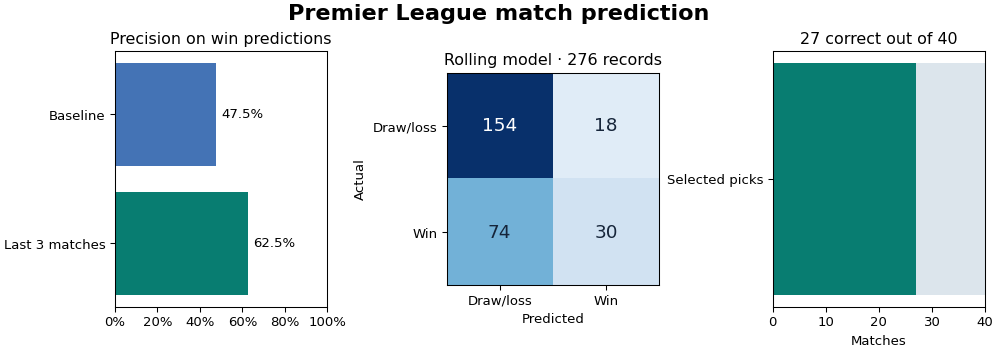

Baseline precision: 47.46% | Rolling precision: 62.50%


In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

baseline_precision = precision_score(baseline["target"], baseline["prediction"], zero_division=0)
rolling_precision = precision_score(rolling["target"], rolling["prediction"], zero_division=0)
matrix = confusion_matrix(rolling["target"], rolling["prediction"], labels=[0, 1])
fig, (left, center, right) = plt.subplots(1, 3, figsize=(10.5, 3.7), layout="constrained")
fig.suptitle("Premier League match prediction", fontsize=17, fontweight="bold")
bars = left.barh(["Baseline", "Last 3 matches"], [baseline_precision, rolling_precision],
                 color=["#4473B5", "#087D71"])
left.bar_label(bars, [f"{p:.1%}" for p in [baseline_precision, rolling_precision]], padding=4)
left.invert_yaxis()
left.set(title="Precision on win predictions", xlim=(0, 1))
left.xaxis.set_major_formatter(PercentFormatter(1))
center.imshow(matrix, cmap="Blues", vmin=0)
for row in range(2):
    for col in range(2):
        value = matrix[row, col]
        center.text(col, row, str(value), ha="center", va="center", fontsize=14,
                    color="white" if value > matrix.max() / 2 else "#16253A")
center.set(title=f"Rolling model · {len(rolling)} records", xlabel="Predicted", ylabel="Actual",
           xticks=[0, 1], yticks=[0, 1],
           xticklabels=["Draw/loss", "Win"], yticklabels=["Draw/loss", "Win"])
right.barh(["Selected picks"], [correct], color="#087D71", height=.45)
right.barh(["Selected picks"], [total - correct], left=[correct], color="#DCE5EC", height=.45)
right.set(title=f"{correct} correct out of {total}", xlabel="Matches", xlim=(0, max(total, 1)))
plt.show()
print(f"Baseline precision: {baseline_precision:.2%} | Rolling precision: {rolling_precision:.2%}")

Win precision is the share of predicted wins that actually happened. The paired result measures only the fixtures selected by the agreement rule, so its precision describes a narrower evaluation group.